In [10]:
import numpy as np
import matplotlib.pyplot as plt

plt.style.use("plots.mplstyle")
np.random.seed(42)

In [11]:
import src.functions_generator as fg
import src.heat1D_crank_nicolson_solver as cns

In [12]:
# Parametri simulazione
L = 1
Tf = 10
nt = 1000
D = 1
wanted_r = 0.5
h = 1

# Inizializza solver
solver = cns.Heat1DCrankNicolson(L,Tf,nt,D,h,wanted_r=wanted_r)
solver.info()


-----------------------------Solver info------------------------------

Time scale coeff:                                             1.00e+00
dx:                                                           1.43e-01
dt:                                                           1.00e-02
nt:                                                               1000
nx:                                                                  8
r:                                                            4.90e-01
h:                                                            1.00e+00


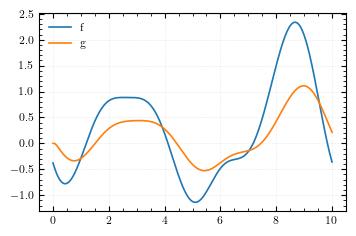

In [13]:
f_generator = fg.FunctionsGenerator(solver.t_array, l=1)

f = f_generator.generate_from_white_noise()

theta = solver.solve(f)
g = theta[solver.nx-1,:]

plt.plot(solver.t_array, f, label="f")
plt.plot(solver.t_array, g, label="g")
plt.legend()
plt.grid()
plt.minorticks_on()
plt.show()

In [14]:
from src.tickonov_handler import TickonovHandler

In [15]:
th = TickonovHandler(solver)

#f_reconstructed = th.tick_impulse_response(g)

f_reconstructed = th.tick_closed_form(g)

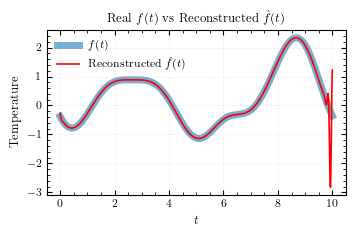

In [16]:
plt.figure()
plt.plot(solver.t_array, f, label=r"$f(t)$", lw=5, alpha=0.6)
plt.plot(solver.t_array, f_reconstructed, label=r"Reconstructed $\hat{f}(t)$", c="r")
plt.xlabel(r"$t$")
plt.ylabel("Temperature")
plt.title(r"Real $f(t)$ vs Reconstructed $\hat{f}(t)$")
plt.grid()
plt.legend()
plt.minorticks_on()
plt.savefig("assets/tikonov_reconstructed_function.pdf")
plt.show()

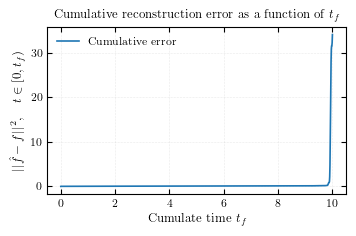

In [17]:
loss_array = np.zeros(nt)

for n in range(nt):
    loss_array[n] = np.linalg.norm(f[0:n] - f_reconstructed[0:n])**2

plt.figure()
plt.plot(solver.t_array, loss_array, label="Cumulative error")
plt.ylabel(r"$||\hat{f} - f||^2, \hspace{1em} t \in [0,t_f)$")
plt.xlabel(r"Cumulate time $t_f$")
plt.title(r"Cumulative reconstruction error as a function of $t_f$")
plt.legend()
plt.grid()
plt.show()

## Test al variare della correlazione temporale

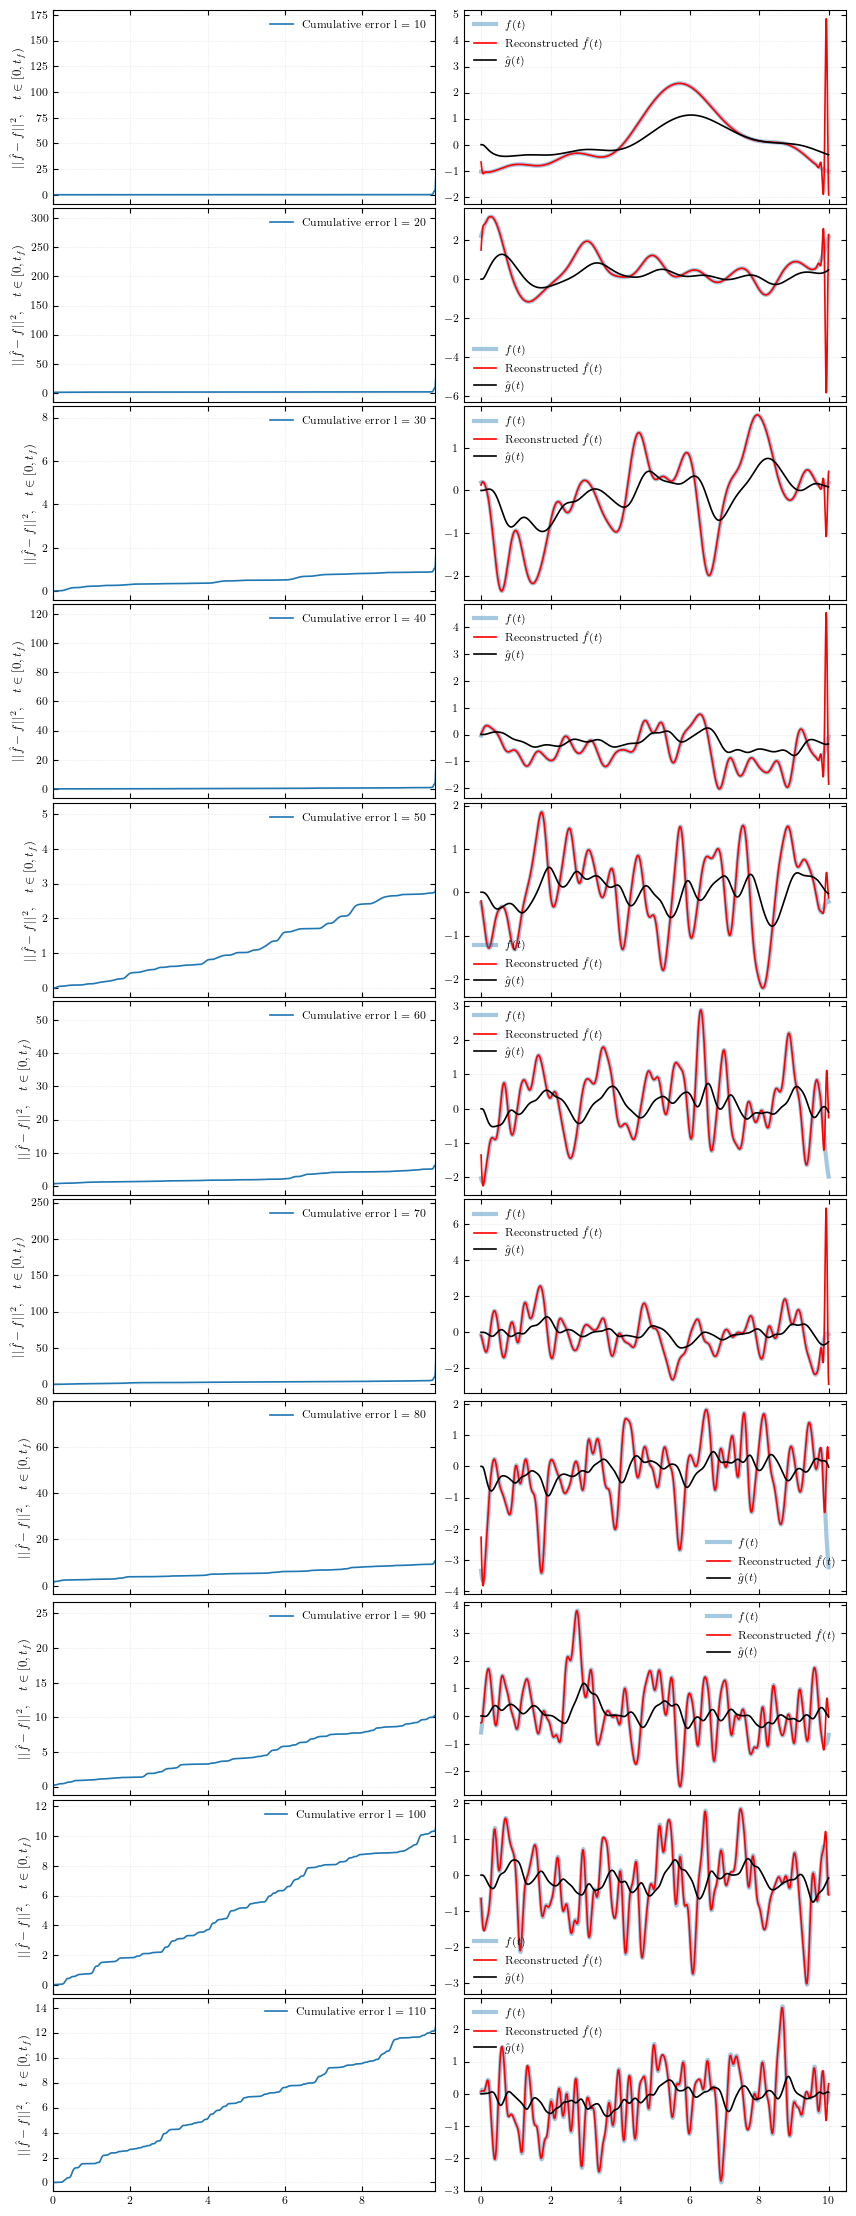

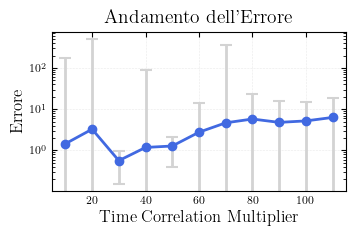

In [22]:
f_generator = fg.FunctionsGenerator(solver.t_array, l=1)
loss_array = np.zeros(nt)

impulse_response = solver.impulse_response()[-1]

time_correlation_multiplier_array = range(10,120,10)
n_corr =  np.size(time_correlation_multiplier_array)

errors_array_mean = np.zeros(n_corr)
errors_array_var = np.zeros(n_corr)

fig, axes = plt.subplots(n_corr,2, figsize=(8.4, 2*n_corr),sharex="col")
i = 0
for time_correlation_multiplier in time_correlation_multiplier_array:
    
    f_generator.l = solver.Tf/time_correlation_multiplier
    f = f_generator.generate_from_white_noise()
    
    g_target = solver.solve_from_impulse_response(f, impulse_response)
    
    f_reconstructed = th.tick_closed_form(g_target)
    
    for n in range(nt):
        loss_array[n] = np.linalg.norm(f[0:n] - f_reconstructed[0:n])**2
        
    axes[i][0].plot(solver.t_array, loss_array, label=f"Cumulative error l = {time_correlation_multiplier}")
    axes[i][0].set_ylabel(r"$||\hat{f} - f||^2, \hspace{1em} t \in [0,t_f)$")
    axes[i][0].set_xlim([0, (solver.nt - 10)*solver.dt])
    axes[i][0].legend()
    axes[i][0].grid()
    
    axes[i][1].plot(solver.t_array, f, label=r"$f(t)$", lw=3, alpha=0.4)
    axes[i][1].plot(solver.t_array, f_reconstructed, label=r"Reconstructed $\hat{f}(t)$", c="r")
    axes[i][1].plot(solver.t_array, g_target, label=r"$\hat{g}(t)$", c="k")
    axes[i][1].legend()
    axes[i][1].grid()
    
    errors_array_mean[i] = np.mean(loss_array)
    errors_array_var[i] = np.var(loss_array)
    
    i = i + 1

plt.show()

plt.errorbar(
    time_correlation_multiplier_array,
    errors_array_mean,
    yerr=errors_array_var,
    fmt='o-',                 
    color='royalblue',        
    ecolor='lightgray',       
    elinewidth=2,
    capsize=4,                
    capthick=1.5,
    markersize=6,
    linewidth=2,
    label='Errore medio'
)

plt.grid()
plt.yscale("log")
plt.xlabel('Time Correlation Multiplier', fontsize=12)
plt.ylabel('Errore', fontsize=12)
plt.title('Andamento dell’Errore', fontsize=14)
plt.show()